# Association and Inferential Statistics

The sleep dataset is **synthetic**. We treat its 100,000 rows as a finite teaching population, not as evidence about real patients. One row represents one person. The supplied 500-person sample is a simple random sample without replacement from this file.

Source: [author's repository](https://github.com/mohan13krishna/Sleep-Health-Daily-Performance-Dataset), associated with the [Kaggle dataset](https://www.kaggle.com/datasets/mohankrishnathalla/sleep-health-and-daily-performance-dataset).



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

population = pd.read_csv("data/sleep_health_population.csv")
sample = pd.read_csv("data/sleep_health_sample_500.csv")
display(sample.head())

,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,wake_episodes_per_night,caffeine_mg_before_bed,alcohol_units_before_bed,screen_time_before_bed_mins,exercise_day,steps_that_day,nap_duration_mins,stress_score,work_hours_that_day,chronotype,mental_health_condition,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,24287,28,Male,Nurse,22.1,USA,5.95,3.4,16.9,25.0,10,3,0,0.0,50,1,5861,56,7.6,8.4,Morning,Healthy,71,0,0,20.8,0.99,Spring,Weekday,63.8,Healthy,0
1,42655,19,Female,Nurse,21.6,India,7.61,6.7,20.6,29.1,14,0,0,0.0,31,1,5836,0,4.5,11.6,Neutral,Healthy,69,1,0,26.4,0.66,Spring,Weekend,99.0,Healthy,0
2,81621,46,Male,Lawyer,32.7,USA,6.90,6.1,22.5,25.6,18,3,0,0.0,40,1,7248,5,5.9,10.4,Evening,Healthy,63,1,0,22.2,1.55,Summer,Weekday,91.4,Healthy,0
3,79266,40,Male,Doctor,24.6,UK,9.03,5.8,17.8,20.8,5,5,0,2.0,31,0,4771,0,5.3,7.6,Neutral,Depression,74,1,0,17.2,-0.22,Autumn,Weekend,57.5,Mild,1
4,95520,19,Female,Freelancer,36.4,South Korea,8.44,6.3,15.1,20.6,18,7,0,0.0,24,0,2103,13,4.1,4.8,Evening,Healthy,73,0,0,25.7,1.21,Summer,Weekend,75.5,Healthy,0


#supplement to exploratory analysis
## 1. Choose a measure based on meaning, not storage type

A column stored as an integer is not necessarily quantitative.

| Measurement scale | Meaning | Example |
|---|---|---|
| Nominal | Categories without an intrinsic order | Occupation, country |
| Ordinal | Ordered categories; gaps are not known to be equal | Healthy < Mild < Moderate < Severe |
| Interval | Equal differences; zero is conventional | Temperature in °C |
| Ratio | Equal differences and a meaningful zero | Sleep duration in hours |

Binary indicators such as `shift_work` are categorical even when stored as 0 and 1. Scores such as `stress_score` require a measurement justification: decimal values alone do not establish equal intervals.

| Variables | Useful measure | What it describes |
|---|---|---|
| Two quantitative variables | Pearson's r | Linear association |
| Ordered or quantitative variables | Spearman's rho | Monotonic association using ranks |
| Ordered variables, especially with ties | Kendall's tau-b | Concordant versus discordant pairs, adjusted for ties |
| Two nominal variables | Cramér's V | Association in a contingency table |
| Two binary variables | Phi | Signed association; direction depends on coding |
| Binary + quantitative | Point-biserial r | Standardized association with group membership |
| Nominal + quantitative | Eta-squared | Fraction of observed variation accounted for by group mean differences |

Association is descriptive here. A coefficient does not establish causation. Its sign, where defined, depends on the direction of the scales or binary coding.

## 2. Pearson: a linear relationship

Pearson's r ranges from −1 to 1. Values near ±1 indicate a strong linear relationship; a value near zero does not rule out a nonlinear relationship.

Inspect the scatter plot before interpreting the coefficient. Outliers can have a large influence. Normality is not required to calculate r; inferential procedures for r have additional assumptions. We report the coefficient only in this section.

The sample coefficient is

$$
r=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2\sum_{i=1}^{n}(y_i-\bar{y})^2}}.
$$

Here $x_i,y_i$ are the paired observations and $\bar{x},\bar{y}$ are their sample means. The numerator measures whether deviations from the means tend to have the same sign; the denominator standardizes the result. Both variables must have nonzero variation.



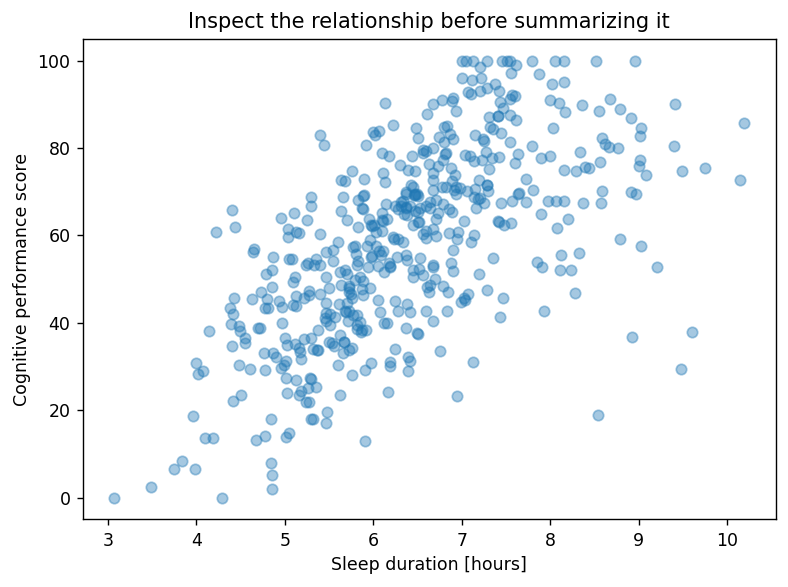

Pearson r: 0.634


In [2]:
sleep_hours = sample["sleep_duration_hrs"]
cognitive_score = sample["cognitive_performance_score"]
r = stats.pearsonr(sleep_hours, cognitive_score).statistic
print(f"Pearson r: {r:.3f}")

plt.scatter(sleep_hours, cognitive_score, alpha=0.4)
plt.xlabel("Sleep duration [hours]")
plt.ylabel("Cognitive performance score")
plt.title("Inspect the relationship before summarizing it")
plt.tight_layout()
plt.show()

## 3. Spearman and Kendall: order matters

Encode `sleep_disorder_risk` in its meaningful order. These numbers represent ranks, not equal clinical distances. Both measures describe **monotonic association**: one variable tends to increase or decrease as the other increases. They do not detect every nonlinear relationship.

### Spearman's rho

Spearman's rho is Pearson correlation applied to ranks:

$$
\rho_s=\operatorname{corr}(R_x,R_y).
$$

$R_x$ and $R_y$ are ranks, with average ranks assigned to tied observations. If there are **no ties**, the equivalent shortcut is

$$
\rho_s=1-\frac{6\sum_{i=1}^{n}d_i^2}{n(n^2-1)},
$$

where $d_i=R_{x,i}-R_{y,i}$. With ties, use the rank-correlation definition, as SciPy does, rather than applying this shortcut unchanged.

### Kendall's tau: compare pairs of people

Consider every unordered pair of people:

- **Concordant:** the person with the higher value of one variable also has the higher value of the other.
- **Discordant:** the ordering is reversed.
- **Tie:** the people share a value in at least one variable.

For example, comparing (sleep hours, test points), the observations (6, 60) and (8, 85) are concordant; (7, 90) and (8, 85) are discordant; (8, 85) and (8, 75) are tied in sleep duration.

Let $C$ be the number of concordant pairs, $D$ the number of discordant pairs, and $n$ the number of people. The variants use the same numerator $C-D$ but different denominators.

#### Tau-a: no correction for ties

$$
\tau_a=\frac{C-D}{\binom n2},
\qquad \binom n2=\frac{n(n-1)}2.
$$

All pairs remain in the denominator, while tied pairs contribute nothing to the numerator. Tau-a is most natural for rankings without ties; when ties occur it cannot reach ±1.

#### Tau-b: adjust for ties in each variable

$$
\tau_b=\frac{C-D}{\sqrt{(C+D+T_x)(C+D+T_y)}}.
$$

$T_x$ counts pairs tied **only in x**, and $T_y$ pairs tied **only in y**. Pairs tied in both variables are not counted in either. This adjustment changes the normalization; it does not break ties or change the data. **Tau-b is our default for ordinal observations with repeated values.** It can still be below 1 when there are no discordant pairs if the variables distinguish different sets of pairs.

#### Tau-c: adjust for the number of categories

Also called **Stuart's tau-c**,

$$
\tau_c=\frac{2m(C-D)}{n^2(m-1)},
$$

where $m$ is the smaller of the two numbers of distinct observed values. Tau-c is useful for ordinal contingency tables, especially when the variables have different numbers of categories. It uses a category-based normalization rather than tau-b's explicit tie counts. It does not create an order for nominal categories.

| Variant | Normalization | Typical use |
|---|---|---|
| Tau-a | Total number of pairs | Rankings without ties |
| Tau-b | Counts of ties in each variable | General ordinal analysis with ties |
| Tau-c | Sample size and smaller category count | Ordinal tables with different category counts |

Without ties, all three coincide. Different values with ties reflect different normalizations, not evidence that the largest coefficient is the best one.

**Small example:** for `x = [1, 2, 3, 4]` and `y = [1, 1, 2, 2]`, there are four concordant pairs, no discordant pairs and two pairs tied only in y. The results are $\tau_a=4/6\approx0.667$, $\tau_b=4/\sqrt{24}\approx0.816$, and $\tau_c=1$. The same observations produce different coefficients because the denominators differ.

SciPy supports `variant="b"` and `variant="c"`; tau-a is not a separate option. See the [SciPy definitions](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kendalltau.html). The worked code below keeps tau-b.


In [3]:
risk_rank = sample["sleep_disorder_risk"].map(
    {"Healthy": 0, "Mild": 1, "Moderate": 2, "Severe": 3}
)
stress = sample["stress_score"]

rho = stats.spearmanr(stress, risk_rank).statistic
tau = stats.kendalltau(stress, risk_rank, variant="b").statistic
print(f"Spearman rho: {rho:.3f}")
print(f"Kendall tau-b: {tau:.3f}")

Spearman rho: 0.514
Kendall tau-b: 0.415


## 4. Nominal variables: do not correlate arbitrary codes

Occupation has no natural order. Replacing occupations with 0, 1, 2, ... does not create a quantitative scale. Pearson and Spearman correlations of these codes have no meaningful interpretation: a different arbitrary assignment can change the result.

For two nominal variables, use a contingency table and **Cramér's V**. V ranges from 0 to 1 and has no positive/negative direction. Its sample estimate can be positive even when the population variables are independent, especially with small samples or many categories.

For a table with $R$ rows and $K$ columns,

$$
E_{ij}=\frac{O_{i+}O_{+j}}{n},
\qquad
\chi^2=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},
\qquad
V=\sqrt{\frac{\chi^2}{n\min(R-1,K-1)}}.
$$

$O_{ij}$ is the observed cell count, $O_{i+}$ and $O_{+j}$ are the row and column totals, and $E_{ij}$ is the expected count under independence. We use the uncorrected Pearson $\chi^2$ statistic to calculate V. Calculation of V is descriptive; an asymptotic chi-square **test** additionally requires suitable sampling assumptions and adequate expected counts. V ignores category order, even if one variable is ordinal.



In [4]:
# Demonstrate the problem: both assignments encode the same occupations.
occupations = sorted(sample["occupation"].unique())
codes_a = sample["occupation"].map(dict(zip(occupations, range(len(occupations)))))
random_codes = np.random.default_rng(12).permutation(len(occupations))
codes_b = sample["occupation"].map(dict(zip(occupations, random_codes)))

print("Invalid Pearson with coding A:", stats.pearsonr(codes_a, sleep_hours).statistic)
print("Invalid Pearson with coding B:", stats.pearsonr(codes_b, sleep_hours).statistic)

# Meaningful nominal association: occupation versus sleep disorder risk.
table = pd.crosstab(sample["occupation"], sample["sleep_disorder_risk"])
v = stats.contingency.association(table, method="cramer", correction=False)
print(f"Cramér's V: {v:.3f}")
display(table)

sleep_disorder_risk,Healthy,Mild,Moderate,Severe
occupation,,,,
Doctor,15,18,2,1
Driver,12,12,4,2
Freelancer,19,12,0,1
Homemaker,14,8,0,0
Lawyer,11,16,2,1
Manager,21,10,4,1
Nurse,12,34,7,6
Retired,29,6,1,0
Sales,20,13,1,2


Invalid Pearson with coding A: -0.024905865181517967
Invalid Pearson with coding B: -0.07608499929252835
Cramér's V: 0.195


## 5. Binary and mixed variable types

For two 0/1 indicators, Pearson correlation equals **phi**. This is meaningful because there are only two groups; their coding controls the sign. For a binary indicator and a quantitative variable, it equals **point-biserial correlation**.

For occupation and sleep duration, **eta-squared** compares variation between group means with total variation. It ranges from 0 to 1, has no direction, and does not summarize differences in distributional shape or variance. This is a descriptive association, not a causal explanation.

### Phi: two binary variables

For a 2×2 table with rows $x=0,1$ and columns $y=0,1$,

| | y = 0 | y = 1 |
|---|---:|---:|
| x = 0 | a | b |
| x = 1 | c | d |

$$
\phi=\frac{ad-bc}{\sqrt{(a+b)(c+d)(a+c)(b+d)}}.
$$

Phi equals Pearson r for the 0/1 indicators. Reversing one indicator's coding reverses the sign. For a nondegenerate 2×2 table, Cramér's V equals $|\phi|$.

### Point-biserial correlation: binary and quantitative

$$
r_{pb}=\frac{\bar{y}_1-\bar{y}_0}{s_{y,n}}\sqrt{p(1-p)},
\qquad p=\frac{n_1}{n}.
$$

$\bar{y}_1$ and $\bar{y}_0$ are the quantitative-variable means in groups 1 and 0. Here $s_{y,n}=\sqrt{\sum_i(y_i-\bar y)^2/n}$ uses divisor **n**, so this formula agrees exactly with Pearson r. A positive coefficient means a higher mean in group 1. This coefficient is descriptive; for inference about a mean difference with unequal variances, use the Welch procedure below.

### Eta-squared: nominal and quantitative

$$
\eta^2=
\frac{\sum_{g=1}^{G} n_g(\bar{y}_g-\bar{y})^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}.
$$

$G$ is the number of groups, $n_g$ the group size, $\bar{y}_g$ its mean, and $\bar{y}$ the overall mean. The numerator is between-group variation and the denominator is total variation. Unlike invented category-code correlations, eta-squared does not change when nominal category names or their code assignments change. Its sample value can increase with many groups and should not be treated as an unbiased population estimate.



In [5]:
phi = stats.pearsonr(sample["exercise_day"], sample["felt_rested"]).statistic
point_biserial = stats.pointbiserialr(sample["shift_work"], sleep_hours).statistic

occupation_summary = sample.groupby("occupation")["sleep_duration_hrs"].agg(["size", "mean"])
between = (occupation_summary["size"] * (occupation_summary["mean"] - sleep_hours.mean())**2).sum()
total = ((sleep_hours - sleep_hours.mean())**2).sum()
eta_squared = between / total

print(f"Phi (exercise / rested): {phi:.3f}")
print(f"Point-biserial r (shift work / sleep): {point_biserial:.3f}")
print(f"Eta-squared (occupation / sleep): {eta_squared:.3f}")

Phi (exercise / rested): 0.010
Point-biserial r (shift work / sleep): -0.196
Eta-squared (occupation / sleep): 0.271


### The same eta-squared with Pingouin

`pingouin.anova(..., effsize="n2")` returns eta-squared as part of a one-way ANOVA table. We select only the descriptive `n2` column here; this does not require interpreting the additional F-test. `n2` requests ordinary eta-squared rather than the default partial eta-squared. With one grouping factor these coincide. The result matches the manual between/total calculation.

In [6]:
import pingouin as pg

anova_result = pg.anova(data=sample, dv="sleep_duration_hrs",
                        between="occupation", effsize="n2")
display(anova_result[["Source", "n2"]])
print(f"Manual eta-squared: {eta_squared:.3f}")

,Source,n2
0,occupation,0.270649


Manual eta-squared: 0.271


# Inferential statistics
## 6. From a sample to a population

**Descriptive statistics** summarizes observed data. **Inferential statistics** uses sample data to estimate population properties and assess uncertainty.

A **parameter** describes a population (for example, its mean). A **statistic** is computed from a sample and can estimate that parameter. Our primary target is the mean sleep duration of everybody in the finite file.

**SRSWOR** means *simple random sampling without replacement*: every possible sample of the chosen size has the same probability, and no person appears twice within a sample. Different repeated samples may overlap.

The next cell illustrates how to draw a sample. We keep the supplied sample for the worked analysis so that everyone sees the same results.

In [7]:
example_sample = population.sample(n=500, replace=False, random_state=42)
print("People in the example sample:", len(example_sample))
print("People in the supplied sample:", len(sample))

People in the example sample: 500
People in the supplied sample: 500


## 7. Individual variation versus uncertainty of a mean

- **SD (standard deviation):** how much individual sleep durations vary.
- **SE (standard error):** how much the estimated mean would vary across repeated samples.

Larger samples usually reduce SE; they do not make people more alike. In the code, `ddof=1` divides the sum of squared deviations by n−1. This makes the sample variance an unbiased estimate of population variance under ordinary iid sampling.

The simulation below draws 500 different people per sample, repeats this 1,000 times, and records each mean. In an actual study the full population is usually unavailable; here it allows us to demonstrate sampling variability.

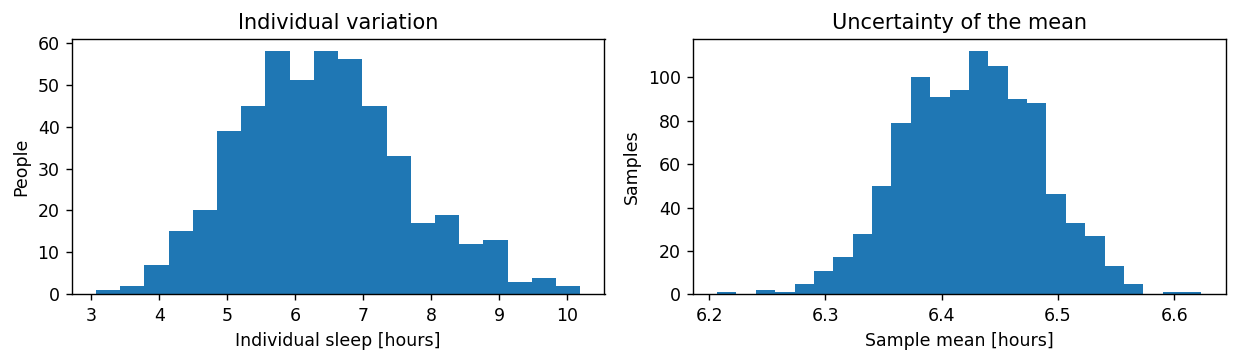

Sample mean: 6.403 hours
Sample SD: 1.229 hours
SD of repeated sample means: 0.058 hours


In [8]:
sleep = sample["sleep_duration_hrs"].to_numpy()
print(f"Sample mean: {sleep.mean():.3f} hours")
print(f"Sample SD: {sleep.std(ddof=1):.3f} hours")

rng = np.random.default_rng(1101)
sampling_means = []
for repetition in range(1000):
    selected = rng.choice(population["sleep_duration_hrs"], size=500, replace=False)
    sampling_means.append(selected.mean())

print(f"SD of repeated sample means: {np.std(sampling_means, ddof=1):.3f} hours")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(sleep, bins=20)
axes[0].set(xlabel="Individual sleep [hours]", ylabel="People", title="Individual variation")
axes[1].hist(sampling_means, bins=25)
axes[1].set(xlabel="Sample mean [hours]", ylabel="Samples", title="Uncertainty of the mean")
plt.tight_layout()
plt.show()

## 8. A 95% confidence interval for the mean

From one sample, estimate the standard error and construct an approximate t-interval:

$$
SE=\frac{s}{\sqrt n}\sqrt{1-\frac nN},
\qquad
\bar{x}\pm t_{0.975,n-1}SE.
$$

Here $s$ is sample SD, $n$ is sample size, and $N$ is population size. The square-root factor is the **finite-population correction** for sampling without replacement. It is about 0.9975 for 500 out of 100,000 people. Observing the whole population would remove sampling uncertainty about its mean.

`stats.t.ppf(0.975, df=n-1)` returns a theoretical t-quantile: 97.5% of that distribution lies below it. The central 95% leaves 2.5% in each tail.

**Interpretation:** across repeated samples, approximately 95% of intervals constructed this way would contain the fixed population mean. This is not a range containing 95% of individuals.

**Assumptions:** the stated random sampling design and a sufficiently accurate t/normal approximation for the sample mean. Small samples with strong skewness or influential values may give poor coverage. This finite-population interval is approximate, not an exact result for arbitrary populations.

In [9]:
sleep = sample["sleep_duration_hrs"].to_numpy()
n = len(sleep)
sd = sleep.std(ddof=1)
se = sd / np.sqrt(n) * np.sqrt(1 - n / len(population))
critical = stats.t.ppf(0.975, df=n - 1)
mean_lower = sleep.mean() - critical * se
mean_upper = sleep.mean() + critical * se

print(f"Mean: {sleep.mean():.3f} hours; SD: {sd:.3f}; SE: {se:.3f}")
print(f"Approximate 95% t-interval: [{mean_lower:.3f}, {mean_upper:.3f}] hours")
print(f"Population reference, revealed afterwards: {population['sleep_duration_hrs'].mean():.3f} hours")

Mean: 6.403 hours; SD: 1.229; SE: 0.055
Approximate 95% t-interval: [6.295, 6.511] hours
Population reference, revealed afterwards: 6.424 hours


### The same t-interval with SciPy

`stats.sem()` calculates the ordinary standard error with `ddof=1` by default. `stats.t.interval()` supplies the two limits directly. Neither function infers the sampling design, so the finite-population correction must still be supplied explicitly in `scale`.

The first interval below matches the manual calculation. The second is the usual iid-style interval **without** the correction. They are close because the sampling fraction is only 0.5%.

In [10]:
mean_ci_function = stats.t.interval(
    confidence=0.95, df=len(sleep) - 1, loc=sleep.mean(),
    scale=stats.sem(sleep) * np.sqrt(1 - len(sleep) / len(population))
)
iid_mean_ci = stats.t.interval(
    confidence=0.95, df=len(sleep) - 1,
    loc=sleep.mean(), scale=stats.sem(sleep)
)
display(pd.DataFrame({
    "method": ["Manual with FPC", "SciPy with FPC", "SciPy without FPC"],
    "lower": [mean_lower, mean_ci_function[0], iid_mean_ci[0]],
    "upper": [mean_upper, mean_ci_function[1], iid_mean_ci[1]]
}))

,method,lower,upper
0,Manual with FPC,6.295399,6.510761
1,SciPy with FPC,6.295399,6.510761
2,SciPy without FPC,6.295128,6.511032


## 9. Bootstrap: another interval for the same mean

A standard nonparametric bootstrap resamples **the observed sample**, with replacement. Each resample has the same number of values as the original sample. Some people appear repeatedly, others are omitted.

1. Generate 2,000 resamples.
2. Compute a mean for each resample.
3. Use the 2.5% and 97.5% quantiles of these means as the interval limits.

These are quantiles of **means**, not quantiles of individual sleep durations. They enclose the central 95% of bootstrap means and form a **percentile bootstrap interval**. Both this and the t-method produce a confidence interval for the same population mean.

**IID** means independent and identically distributed. The ordinary bootstrap approximates iid sampling; it does not exactly reproduce finite-population sampling without replacement. At our 0.5% sampling fraction this distinction is small. It matters for large sampling fractions. Bootstrap does not repair selection bias or dependence, and percentile intervals may be inaccurate for small or strongly skewed samples.

Setting `replace=False` would not solve this: taking n of n observations without replacement gives the same mean every time.

,method,lower,upper
0,Finite-population t,6.295399,6.510761
1,Percentile bootstrap,6.299370,6.505580


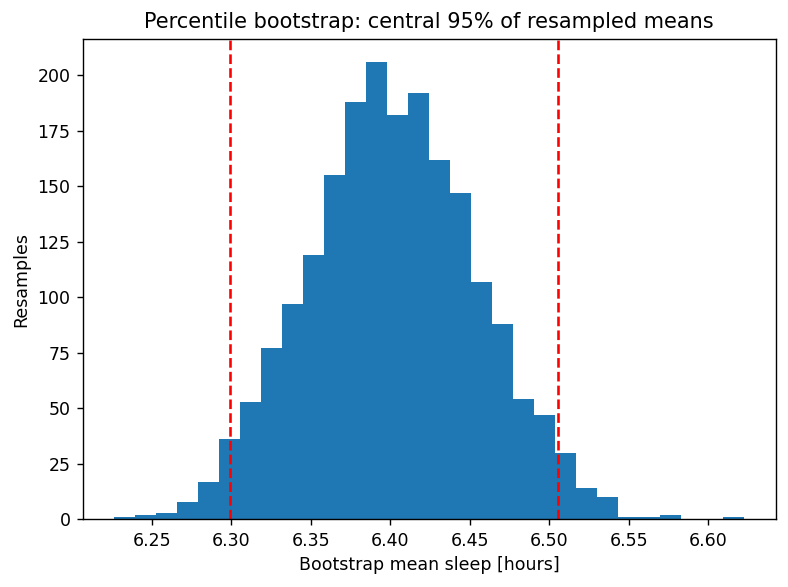

In [11]:
sleep = sample["sleep_duration_hrs"].to_numpy()
rng = np.random.default_rng(1105)
bootstrap_means = []
for repetition in range(2000):
    resample = rng.choice(sleep, size=len(sleep), replace=True)
    bootstrap_means.append(resample.mean())

bootstrap_lower, bootstrap_upper = np.quantile(bootstrap_means, [0.025, 0.975])
display(pd.DataFrame({
    "method": ["Finite-population t", "Percentile bootstrap"],
    "lower": [mean_lower, bootstrap_lower],
    "upper": [mean_upper, bootstrap_upper]
}))
plt.hist(bootstrap_means, bins=30)
plt.axvline(bootstrap_lower, color="red", linestyle="--")
plt.axvline(bootstrap_upper, color="red", linestyle="--")
plt.xlabel("Bootstrap mean sleep [hours]")
plt.ylabel("Resamples")
plt.title("Percentile bootstrap: central 95% of resampled means")
plt.tight_layout()
plt.show()

### The same percentile bootstrap with SciPy

`stats.bootstrap()` performs the resampling, applies the statistic, and returns its interval. `(sleep,)` is a tuple containing one dataset; `np.mean` specifies the statistic to compute.

Specify `method="percentile"` to match our quantile method: SciPy otherwise defaults to **BCa**, a different interval method. We use 2,000 resamples and a fresh seeded generator. Implementations may generate different individual resamples, so small Monte Carlo differences in limits are possible. The same iid approximation and finite-population limitations apply.

In [12]:
bootstrap_result = stats.bootstrap(
    (sleep,), np.mean, n_resamples=2000, confidence_level=0.95,
    method="percentile", rng=np.random.default_rng(1105)
)
display(pd.DataFrame({
    "method": ["Manual percentile", "SciPy percentile"],
    "lower": [bootstrap_lower, bootstrap_result.confidence_interval.low],
    "upper": [bootstrap_upper, bootstrap_result.confidence_interval.high]
}))

,method,lower,upper
0,Manual percentile,6.29937,6.50558
1,SciPy percentile,6.29937,6.50558


## 10. Precision does not remove selection bias

Increasing a valid random sample generally narrows an interval. Increasing a systematically selected sample can instead give a narrow interval around the wrong target.

The next example deliberately uses only shift workers but pretends they were a random sample of everybody. **The interval is invalid for the overall population mean.** A random sample of shift workers could estimate the shift-worker mean, with the corresponding subgroup sampling design, but that is a different question.

In [13]:
selected = population.loc[population["shift_work"] == 1].sample(n=3000, random_state=7)
values = selected["sleep_duration_hrs"]
# Deliberately wrong design assumption: pretending this represents everybody.
naive_se = values.std(ddof=1) / np.sqrt(len(values)) * np.sqrt(1 - len(values) / len(population))
margin = stats.t.ppf(0.975, df=len(values) - 1) * naive_se
print(f"Selected mean: {values.mean():.3f} hours")
print(f"Invalid overall-population interval: [{values.mean()-margin:.3f}, {values.mean()+margin:.3f}]")
print(f"Actual overall-population mean: {population['sleep_duration_hrs'].mean():.3f} hours")

Selected mean: 5.470 hours
Invalid overall-population interval: [5.429, 5.512]
Actual overall-population mean: 6.424 hours


### A ready-made function does not repair the wrong design

`stats.t.interval()` can replace the arithmetic for the two limits, but the interval remains **invalid for everybody's mean**. It still uses the deliberately inappropriate standard error from the selected subgroup. A package cannot infer representativeness from the values alone.

In [14]:
invalid_ci_function = stats.t.interval(
    confidence=0.95, df=len(values) - 1,
    loc=values.mean(), scale=naive_se
)
print("Still invalid for the overall population:", invalid_ci_function)

Still invalid for the overall population: (np.float64(5.428597180200622), np.float64(5.511656153132709))


## 11. Estimate a proportion: feeling rested

For a binary 0/1 variable, its mean equals the proportion of ones:

$$\hat p=\frac{\text{number of rested people}}{n}.$$

The simple **Wald interval** is $\hat p\pm1.96\sqrt{\hat p(1-\hat p)/n}$. It can have poor coverage, extend beyond [0,1], and collapse to zero width when everybody or nobody reports success.

We use the **Wilson interval**, which stays within [0,1] and generally has more reliable coverage. Its limits are

$$
\frac{\hat p+z^2/(2n)\;\pm\;z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}}{1+z^2/n}.
$$

`stats.norm.ppf(0.975)` gives $z\approx1.96$, the 97.5% quantile of the standard normal distribution. Unlike `np.quantile`, it uses a theoretical distribution rather than observed values.

Wilson assumes independent binary observations with the same success probability. Here it approximates our small-fraction sampling design. The exact finite-population count model is hypergeometric, not binomial. The population reference is revealed only after estimation.

In [15]:
rested = sample["felt_rested"]
n = len(rested)
p = rested.mean()
z = stats.norm.ppf(0.975)

center = (p + z**2 / (2*n)) / (1 + z**2/n)
half_width = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2/n)
print(f"Rested in the sample: {rested.sum()} of {n} ({p:.1%})")
print(f"95% Wilson interval: [{center-half_width:.1%}, {center+half_width:.1%}]")
print(f"Population reference: {population['felt_rested'].mean():.1%}")

Rested in the sample: 173 of 500 (34.6%)
95% Wilson interval: [30.6%, 38.9%]
Population reference: 39.0%


### The same Wilson interval with statsmodels

`proportion_confint()` takes the number of successes and the number of observations. `alpha=0.05` requests a 95% interval; `method="wilson"` explicitly chooses Wilson rather than the default normal (Wald) method. It matches the manual formula and uses the same binomial approximation.

In [16]:
from statsmodels.stats.proportion import proportion_confint

wilson_lower, wilson_upper = proportion_confint(
    count=rested.sum(), nobs=len(rested), alpha=0.05, method="wilson"
)
display(pd.DataFrame({
    "method": ["Manual Wilson", "statsmodels Wilson"],
    "lower": [center - half_width, wilson_lower],
    "upper": [center + half_width, wilson_upper]
}))

,method,lower,upper
0,Manual Wilson,0.305621,0.388727
1,statsmodels Wilson,0.305621,0.388727


## 12. Compare two independent groups

**Question:** what is the difference in population mean sleep duration, shift work minus regular work?

These are different people, not paired before/after measurements. A total of 500 does not imply 250 in each group. Inspect group sizes and distributions first. A Q–Q plot compares observed quantiles with normal-distribution quantiles; departures from a straight line reveal distributional differences, not an automatic pass/fail decision.

,size,mean,std
shift_work,,,
0,462,6.472013,1.210841
1,38,5.565000,1.144287


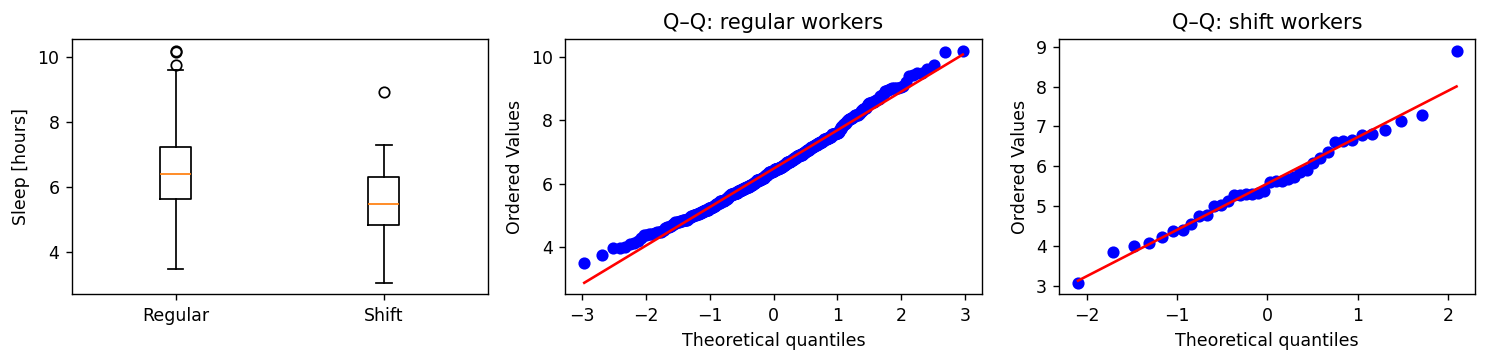

In [17]:
regular = sample.loc[sample["shift_work"] == 0, "sleep_duration_hrs"]
shift = sample.loc[sample["shift_work"] == 1, "sleep_duration_hrs"]
display(sample.groupby("shift_work")["sleep_duration_hrs"].agg(["size", "mean", "std"]))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].boxplot([regular, shift])
axes[0].set_xticks([1, 2], ["Regular", "Shift"])
axes[0].set_ylabel("Sleep [hours]")
stats.probplot(regular, dist="norm", plot=axes[1])
axes[1].set_title("Q–Q: regular workers")
stats.probplot(shift, dist="norm", plot=axes[2])
axes[2].set_title("Q–Q: shift workers")
plt.tight_layout()
plt.show()

### Estimate first, then test

$$
\widehat\Delta=\bar x_1-\bar x_0,
\qquad
SE(\widehat\Delta)=\sqrt{s_1^2/n_1+s_0^2/n_0}.
$$

Group 1 is shift work; group 0 is regular work. A difference of −0.9 hours means 54 minutes less sleep on average in the sampled shift workers.

**Welch's t-test** allows unequal population variances. It uses Welch–Satterthwaite approximate degrees of freedom to choose the t-distribution; they need not be an integer. The two-sided interval is

$$\widehat\Delta\pm t_{0.975,\nu}SE(\widehat\Delta).$$

The code uses SciPy to obtain the same Welch interval and test without writing an additional helper function. The null hypothesis is $H_0:\Delta=0$ and the two-sided alternative is $H_1:\Delta\ne0$.

**Assumptions:** independent observations within and between groups; an appropriate sampling design/model; an adequate t-approximation for the difference in means. Very small groups, strong skewness and influential errors can undermine the approximation. We neglect group-specific finite-population corrections at the small sampling fractions used here.

In [18]:
difference = shift.mean() - regular.mean()
se_difference = np.sqrt(shift.var(ddof=1)/len(shift) + regular.var(ddof=1)/len(regular))

print(f"Manual difference (shift minus regular): {difference:.3f} hours")
print(f"Manual SE of the difference: {se_difference:.3f} hours")

Manual difference (shift minus regular): -0.907 hours
Manual SE of the difference: 0.194 hours


### Welch's interval and test directly with SciPy

The manual lines above estimate the difference and its standard error. `stats.ttest_ind(..., equal_var=False)` carries out Welch's procedure, including the approximate degrees of freedom. Its `confidence_interval()` method returns the corresponding two-sided interval. This ready-made calculation was already present in the notebook; it is separated here to make the sequence explicit. As before, it omits group-specific finite-population corrections.

In [19]:
result = stats.ttest_ind(shift, regular, equal_var=False, alternative="two-sided")
interval = result.confidence_interval(confidence_level=0.95)

print(f"Difference (shift minus regular): {difference:.3f} hours")
print(f"Standard error of the difference: {se_difference:.3f} hours")
print(f"Welch degrees of freedom: {result.df:.2f}")
print(f"95% confidence interval: [{interval.low:.3f}, {interval.high:.3f}] hours")
print(f"Two-sided p-value: {result.pvalue:.4g}")

Difference (shift minus regular): -0.907 hours
Standard error of the difference: 0.194 hours
Welch degrees of freedom: 44.10
95% confidence interval: [-1.298, -0.516] hours
Two-sided p-value: 2.781e-05


## 13. What does the p-value mean?

Under the null hypothesis **and the test assumptions**, the p-value is the probability of a test statistic at least as extreme as the one observed. For a two-sided test, departures in either direction count.

A small p-value indicates incompatibility with the null model. It is **not** the probability that the null is true, the probability that the result is “due to chance”, or a measure of practical importance.

Using the same two-sided Welch procedure:

- A 95% interval excluding zero corresponds to p < 0.05.
- An interval including zero means we do not reject at 0.05; it does not prove equal means.

**Type I error:** rejecting a true null. **Type II error:** failing to reject a false null. **Power:** the probability of rejecting under a specified alternative; it depends on effect size, variability and sample size.

The following separate simulation has equal normal population means. About 5% of valid tests still reject at the 0.05 level. This does not mean that 5% of all significant findings in practice are false.

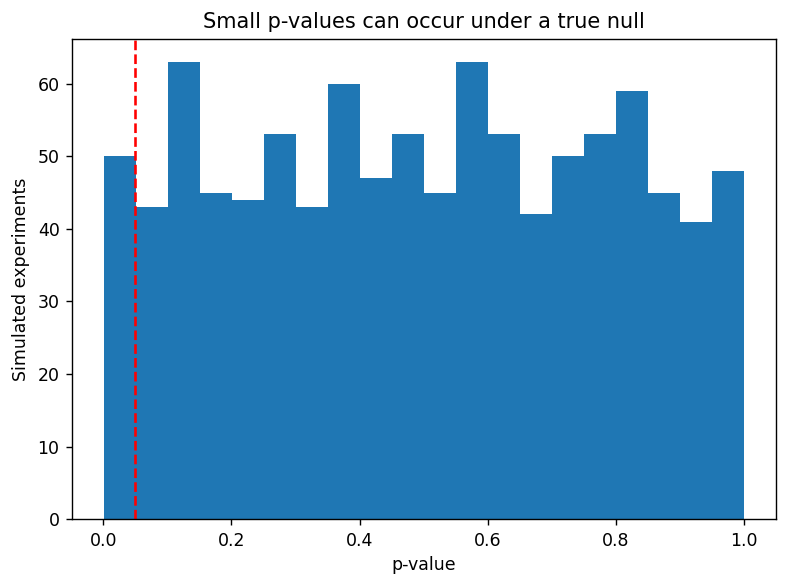

False-positive fraction: 4.8%


In [20]:
rng = np.random.default_rng(1106)
p_values = []
for repetition in range(1000):
    first = rng.normal(size=30)
    second = rng.normal(size=30)
    p_values.append(stats.ttest_ind(first, second, equal_var=False).pvalue)

print(f"False-positive fraction: {(np.array(p_values) < 0.05).mean():.1%}")
plt.hist(p_values, bins=20)
plt.axvline(0.05, color="red", linestyle="--")
plt.xlabel("p-value")
plt.ylabel("Simulated experiments")
plt.title("Small p-values can occur under a true null")
plt.tight_layout()
plt.show()

## 14. Choose a method for the question, not just the histogram

**Parametric** and **nonparametric** describe methods, not data. Parametric methods use a specified model family; nonparametric methods make fewer distributional restrictions, but still have assumptions.

Welch's test concerns **population means**. Mann–Whitney uses ranks and is not automatically a test of medians; interpreting it as a location/median comparison requires additional distributional assumptions. Replacing Welch solely because a normality test rejects can change the question being answered.

**Association is not causation:** shift work was not randomly assigned. Age and occupation may differ between groups and relate to sleep. Random sampling supports population inference, but it does not eliminate confounding.

**Multiple testing:** testing many associations and reporting only small p-values increases false-positive risk. Specify primary questions in advance; label exploratory analyses and consider a suitable multiplicity correction when making several confirmatory claims.

### A short reporting template

> In a random sample of ... people, the estimated [mean / proportion / difference] was ... . The 95% confidence interval was ... using [method]. For the group comparison, the two-sided Welch p-value was ... . The result describes an association; practical importance depends on ... . Main assumptions and limitations were ... .
